# 第六章 针对分类的微调

In [1]:
# 加载GPT_124M模型
import torch
from gpt2 import GPTModel, load_weights_into_gpt
from gpt_download import load_gpt2

GPT_CONFIG_124M = {
    "vocab_size": 50257,  # 词汇表大小
    "context_length": 1024,  # 上下文长度
    "emb_dim": 768,  # 嵌入维度
    "n_heads": 12,  # 注意力头的数量
    "n_layers": 12,  # 层数
    "drop_rate": 0.1,  # dropout率
    "qkv_bias": True  # GPT-2使用了模型偏置
}

# 创建一个新的GPTModel实例
gpt = GPTModel(GPT_CONFIG_124M)
gpt.eval()
# 记载模型文件
settings, params = load_gpt2(
    model_size="124M", models_dir="gpt2"
)
# 加载模型权重
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
load_weights_into_gpt(gpt, params)
gpt.to(device)

2026-10-14 13:13:00.027802: I tensorflow/core/util/port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.
2026-10-14 13:13:00.048021: E external/local_xla/xla/stream_executor/cuda/cuda_fft.cc:467] Unable to register cuFFT factory: Attempting to register factory for plugin cuFFT when one has already been registered
E0000 00:00:1791954780.071438 1594937 cuda_dnn.cc:8579] Unable to register cuDNN factory: Attempting to register factory for plugin cuDNN when one has already been registered
E0000 00:00:1791954780.079124 1594937 cuda_blas.cc:1407] Unable to register cuBLAS factory: Attempting to register factory for plugin cuBLAS when one has already been registered
W0000 00:00:1791954780.099401 1594937 computation_placer.cc:177] computation placer already registered. Please check linkage and avoid linking 

GPTModel(
  (tok_emb): Embedding(50257, 768)
  (pos_emb): Embedding(1024, 768)
  (drop_emb): Dropout(p=0.1, inplace=False)
  (trf_blocks): Sequential(
    (0): TransformerBlock(
      (att): MultiHeadAttention(
        (W_query): Linear(in_features=768, out_features=768, bias=True)
        (W_key): Linear(in_features=768, out_features=768, bias=True)
        (W_value): Linear(in_features=768, out_features=768, bias=True)
        (out_proj): Linear(in_features=768, out_features=768, bias=True)
        (dropout): Dropout(p=0.1, inplace=False)
      )
      (ff): FeedForward(
        (layers): Sequential(
          (0): Linear(in_features=768, out_features=3072, bias=True)
          (1): GELU()
          (2): Linear(in_features=3072, out_features=768, bias=True)
        )
      )
      (norm1): LayerNorm()
      (norm2): LayerNorm()
      (drop_shortcut): Dropout(p=0.1, inplace=False)
    )
    (1): TransformerBlock(
      (att): MultiHeadAttention(
        (W_query): Linear(in_features=7

## 准备数据集
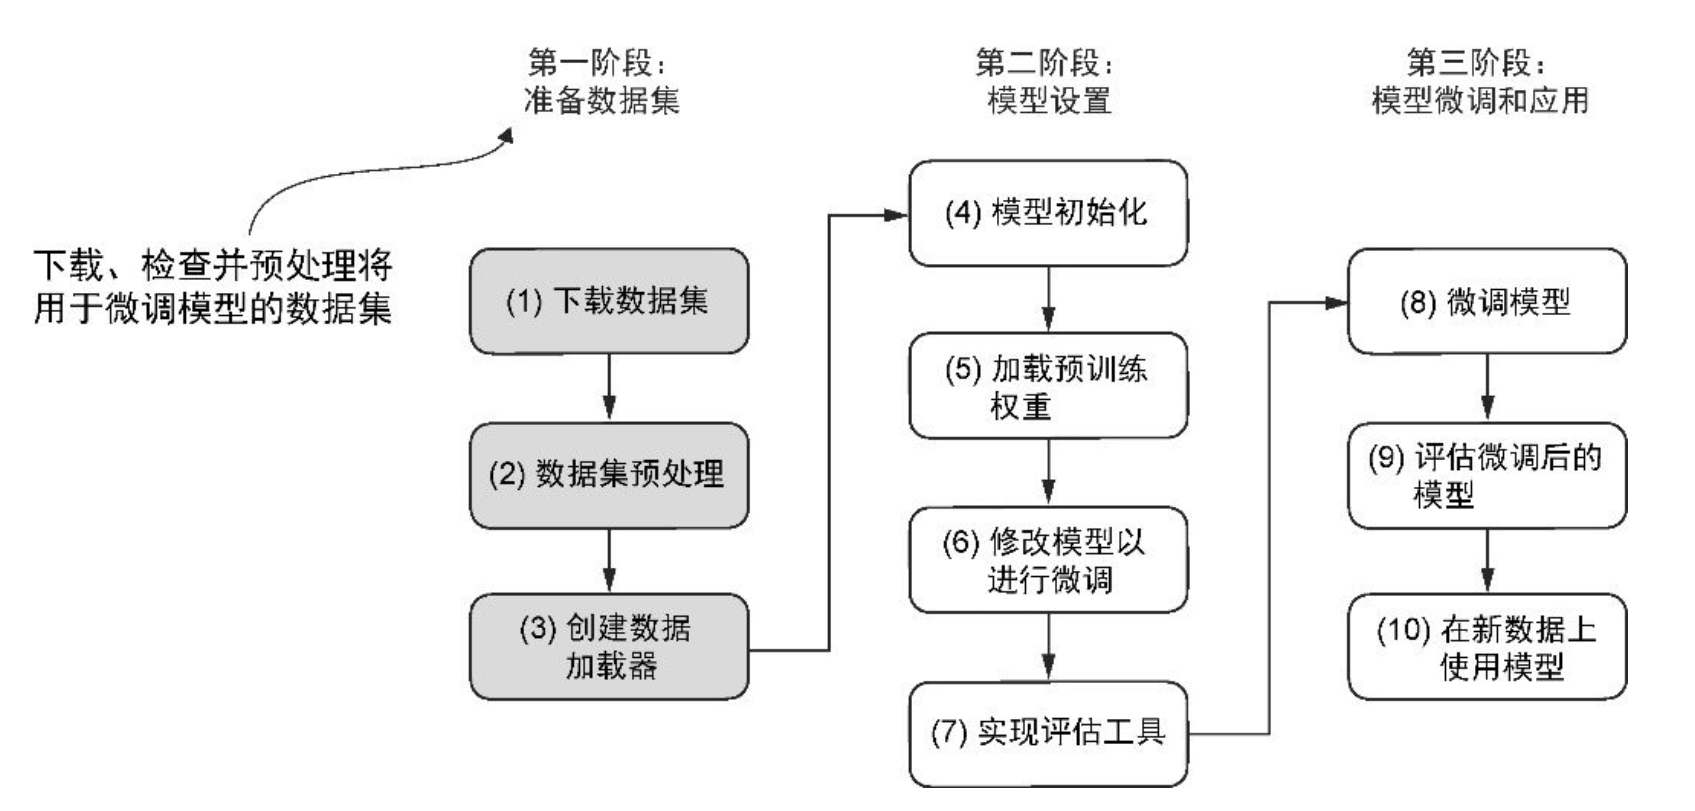

In [2]:
# 下载和解压数据集
import urllib.request
import zipfile
import os
from pathlib import Path

url = "https://archive.ics.uci.edu/static/public/228/sms+spam+collection.zip"
zip_path = "sms_spam_collection.zip"
extracted_path = "sms_spam_collection"
data_file_path = Path(extracted_path) / "SMSSpamCollection.tsv"

def download_and_unzip_spam_data(url, zip_path, extracted_path, data_file_path):
    if data_file_path.exists():
        print(f"{data_file_path} already exists. Skipping download and extraction.")
        return
    # 下载文件
    with urllib.request.urlopen(url) as response:
        with open(zip_path, "wb") as out_file:
            out_file.write(response.read())
    # 解压文件
    with zipfile.ZipFile(zip_path, "r") as zip_ref:
        zip_ref.extractall(extracted_path)
    # 添加.tsv文件扩展名
    original_file_path = Path(extracted_path) / "SMSSpamCollection"
    os.rename(original_file_path, data_file_path)
    print(f"File downloaded and saved as {data_file_path}")

download_and_unzip_spam_data(url, zip_path, extracted_path, data_file_path)

sms_spam_collection/SMSSpamCollection.tsv already exists. Skipping download and extraction.


In [3]:
# 加载数据
import pandas as pd

df = pd.read_csv(
    data_file_path, sep="\t", header=None, names=["Label", "Text"]
)
df

,Label,Text
0,ham,"Go until jurong point, crazy.. Available only ..."
1,ham,Ok lar... Joking wif u oni...
2,spam,Free entry in 2 a wkly comp to win FA Cup fina...
3,ham,U dun say so early hor... U c already then say...
4,ham,"Nah I don't think he goes to usf, he lives aro..."
...,...,...
5567,spam,This is the 2nd time we have tried 2 contact u...
5568,ham,Will ü b going to esplanade fr home?
5569,ham,"Pity, * was in mood for that. So...any other s..."
5570,ham,The guy did some bitching but I acted like i'd...


In [4]:
# 查看类别标签分布
print(df["Label"].value_counts())

Label
ham     4825
spam     747
Name: count, dtype: int64


In [5]:
# 创建一个平衡的数据集
def create_balanced_dataset(df):
    # 统计垃圾消息的样本数量
    num_spam = df[df["Label"] == "spam"].shape[0]
    # 随机采样非垃圾消息，使其数量与垃圾消息一致
    ham_subset = df[df["Label"] == "ham"].sample(
        num_spam, random_state=123
    )
    # 将垃圾消息和采样后的非垃圾消息组合，构成平衡数据集
    balanced_df = pd.concat([
        ham_subset, df[df["Label"] == "spam"]
    ])
    return balanced_df

balanced_df = create_balanced_dataset(df)
print(balanced_df["Label"].value_counts())
# 将类别标签ham和spam转换为整数类别标签0和1
balanced_df["Label"] = balanced_df["Label"].map({"ham": 0, "spam": 1})

Label
ham     747
spam    747
Name: count, dtype: int64


In [6]:
# 划分数据集
def random_split(df, train_frac, validation_frac):
    # 打乱整个Dataframe
    df = df.sample(
        frac=1, random_state=123
    ).reset_index(drop=True)
    train_end = int(len(df) * train_frac)
    validation_end = train_end + int(len(df) * validation_frac)
    train_df = df[:train_end]
    validation_df = df[train_end:validation_end]
    test_df = df[validation_end:]
    return train_df, validation_df, test_df

train_df, validation_df, test_df = random_split(balanced_df, 0.7, 0.1)
# 保存训练接、测试集和验证集
train_df.to_csv("data/train.csv", index=None)
validation_df.to_csv("data/validation.csv", index=None)
test_df.to_csv("data/test.csv", index=None)

In [7]:
# 构建一个Pytorch Dataset类
from torch.utils.data import Dataset

class SpamDataset(Dataset):
    def __init__(self, csv_file, tokenizer, max_length=None, pad_token_id=50256):
        self.data = pd.read_csv(csv_file)
        self.encoded_texts = [
            tokenizer.encode(text) for text in self.data["Text"]
        ]
        if max_length is None:
            self.max_length = self._longest_encoded_length()
        else:
            self.max_length = max_length
            self.encoded_texts = [
                encoded_text[:self.max_length]
                for encoded_text in self.encoded_texts
            ]
        # 填充到最长的序列长度
        self.encoded_texts = [
            encoded_text + [pad_token_id] * (self.max_length - len(encoded_text))
            for encoded_text in self.encoded_texts
        ]

    def __getitem__(self, index):
        encoded = self.encoded_texts[index]
        label = self.data.iloc[index]["Label"]
        return (
            torch.tensor(encoded, dtype=torch.long),
            torch.tensor(label, dtype=torch.long)
        )

    def __len__(self):
        return len(self.data)

    def _longest_encoded_length(self):
        max_length = 0
        for encoded_text in self.encoded_texts:
            encoded_length = len(encoded_text)
            if encoded_length > max_length:
                max_length = encoded_length
        return max_length

In [8]:
# 使用<|endoftext|>进行文本填充
import tiktoken

tokenizer = tiktoken.get_encoding("gpt2")
print(tokenizer.encode("<|endoftext|>", allowed_special={"<|endoftext|>"}))

train_dataset = SpamDataset(
    csv_file="data/train.csv",
    max_length=None,
    tokenizer=tokenizer
)
print(train_dataset.max_length)

[50256]
120


In [9]:
# 将测试集和验证集填充到与最长训练序列的长度
val_dataset = SpamDataset(
    csv_file="data/validation.csv",
    max_length=train_dataset.max_length,
    tokenizer=tokenizer
)
test_dataset = SpamDataset(
    csv_file="data/test.csv",
    max_length=train_dataset.max_length,
    tokenizer=tokenizer
)

In [10]:
# 创建数据加载器
from torch.utils.data import DataLoader

num_workers = 0
batch_size = 8
torch.manual_seed(123)

train_loader = DataLoader(
    dataset=train_dataset,
    batch_size=batch_size,
    shuffle=True,
    num_workers=num_workers,
    drop_last=True
)
val_loader = DataLoader(
    dataset=val_dataset,
    batch_size=batch_size,
    num_workers=num_workers,
    drop_last=False
)
test_loader = DataLoader(
    dataset=test_dataset,
    batch_size=batch_size,
    num_workers=num_workers,
    drop_last=False
)

for input_batch, target_batch in train_loader:
    pass
print("Input batch dimensions:", input_batch.shape)
print("Label batch dimensions", target_batch.shape)

print(f"{len(train_loader)} training batches")
print(f"{len(val_loader)} validation batches")
print(f"{len(test_loader)} test batches")

Input batch dimensions: torch.Size([8, 120])
Label batch dimensions torch.Size([8])
130 training batches
19 validation batches
38 test batches


In [12]:
# 模型微调前测试模型是否已经能够分类垃圾消息
from gpt2 import generate_text_simple, text_to_token_ids, token_ids_to_text

gpt.to("cpu")
text_2 = (
    "Is the following text 'spam'? Answer with 'yes' or 'no':"
    " 'You are a winner you have been specially"
    " selected to receive $1000 cash or a $2000 award.'"
)
token_ids = generate_text_simple(
    model=gpt,
    idx=text_to_token_ids(text_2, tokenizer),
    max_new_tokens=23,
    context_size=GPT_CONFIG_124M["context_length"]
)
print(token_ids_to_text(token_ids, tokenizer))

Is the following text 'spam'? Answer with 'yes' or 'no': 'You are a winner you have been specially selected to receive $1000 cash or a $2000 award.'

The following text 'spam'? Answer with 'yes' or 'no': 'You are a winner


## 添加分类头
通过调整架构使GPT模型适应垃圾消息分类任务。模型初始的线性输出层将768个隐藏单元映射到了拥有50257个词元的词汇表中。为了检测垃圾消息，我们将这个层替换为一个新的输出层，该层将相同的768个隐藏单元映射到了两个类别，分别表示“垃圾消息”和“非垃圾消息”
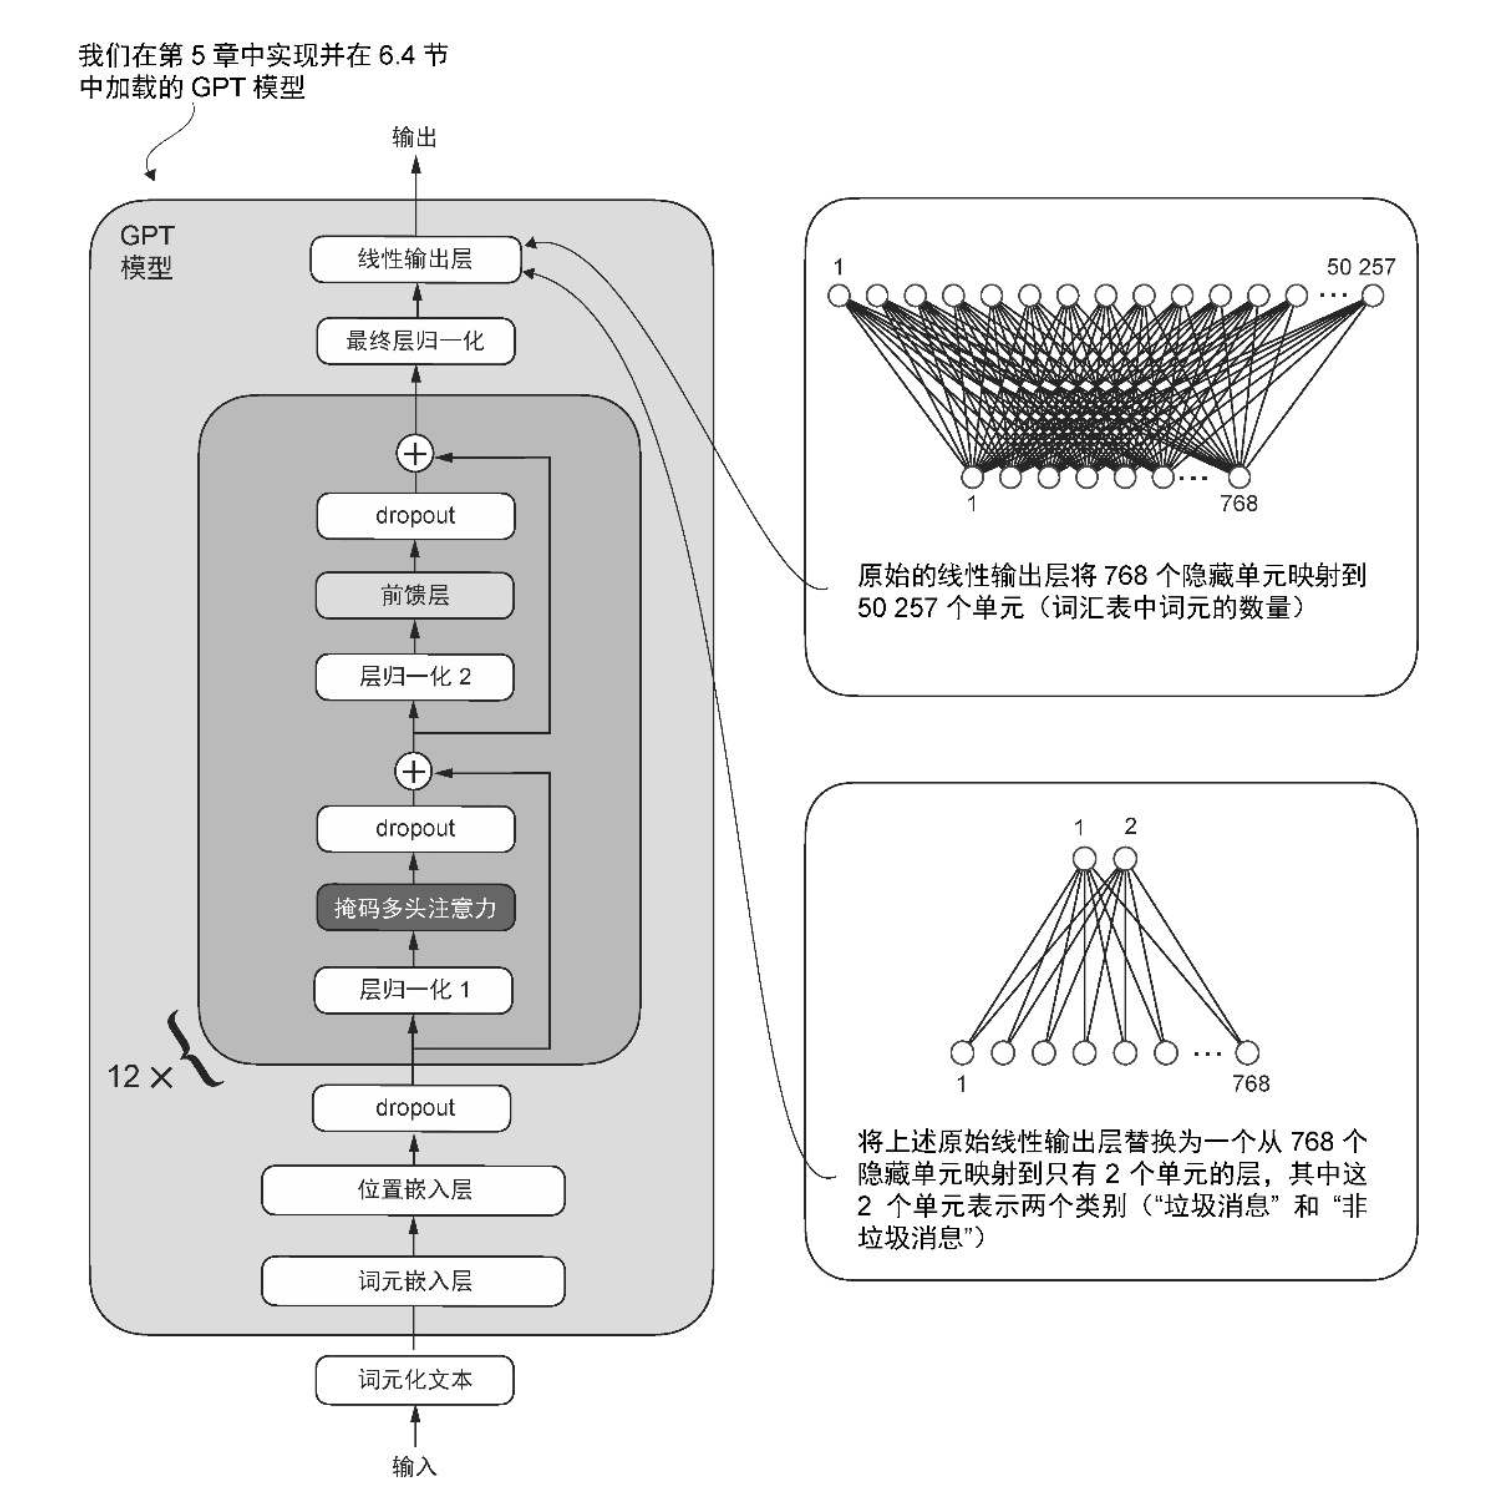

In [13]:
# 打印模型架构
print(gpt)

GPTModel(
  (tok_emb): Embedding(50257, 768)
  (pos_emb): Embedding(1024, 768)
  (drop_emb): Dropout(p=0.1, inplace=False)
  (trf_blocks): Sequential(
    (0): TransformerBlock(
      (att): MultiHeadAttention(
        (W_query): Linear(in_features=768, out_features=768, bias=True)
        (W_key): Linear(in_features=768, out_features=768, bias=True)
        (W_value): Linear(in_features=768, out_features=768, bias=True)
        (out_proj): Linear(in_features=768, out_features=768, bias=True)
        (dropout): Dropout(p=0.1, inplace=False)
      )
      (ff): FeedForward(
        (layers): Sequential(
          (0): Linear(in_features=768, out_features=3072, bias=True)
          (1): GELU()
          (2): Linear(in_features=3072, out_features=768, bias=True)
        )
      )
      (norm1): LayerNorm()
      (norm2): LayerNorm()
      (drop_shortcut): Dropout(p=0.1, inplace=False)
    )
    (1): TransformerBlock(
      (att): MultiHeadAttention(
        (W_query): Linear(in_features=7

In [14]:
# 为了使模型准备好进行分类微调，先冻结模型，将所有层设为不可训练
for param in gpt.parameters():
    param.requires_grad = False

# 添加分类层
torch.manual_seed(123)
num_classes = 2
gpt.out_head = torch.nn.Linear(
    in_features=GPT_CONFIG_124M["emb_dim"],
    out_features=num_classes
)

# 从技术上讲仅训练上面添加的输出层就足够了，但实验发现，微调额外的层可以显著提升模型的预测性能
# 因此这里还将最后一个Transformer块和连接该块到输出层的最终层归一化模块设置为可训练
for param in gpt.trf_blocks[-1].parameters():
    param.requires_grad = True
for param in gpt.final_norm.parameters():
    param.requires_grad = True

In [16]:
# 测试修改输出层后的模型输出
inputs = tokenizer.encode("Do you have time")
inputs = torch.tensor(inputs).unsqueeze(0)
print("Inputs:", inputs)
print("Inputs.shape:", inputs.shape)
with torch.no_grad():
    outputs = gpt(inputs)
print("Outputs:", outputs)
print("Outputs.shape:", outputs.shape)
# 只需关注最后一个输出词元
print("Last output token:", outputs[:, -1, :])
# 输出类别标签
logits = outputs[:, -1, :]
label = torch.argmax(logits)
print("Class label:", label.item())

Inputs: tensor([[5211,  345,  423,  640]])
Inputs.shape: torch.Size([1, 4])
Outputs: tensor([[[-1.5854,  0.9904],
         [-3.7235,  7.4548],
         [-2.2661,  6.6049],
         [-3.5983,  3.9902]]])
Outputs.shape: torch.Size([1, 4, 2])
Last output token: tensor([[-3.5983,  3.9902]])
Class label: 1


In [17]:
# 计算分类准确率
def calc_accuracy_loader(data_loader, model, device, num_batches=None):
    model.eval()
    correct_predictions, num_examples = 0, 0
    if num_batches is None:
        num_batches = len(data_loader)
    else:
        num_batches = min(num_batches, len(data_loader))
    for i, (input_batch, target_batch) in enumerate(data_loader):
        if i<num_batches:
            input_batch = input_batch.to(device)
            target_batch = target_batch.to(device)
            with torch.no_grad():
                logits = model(input_batch)[:, -1, :]
            predicted_labels = torch.argmax(logits, dim=-1)
            num_examples += predicted_labels.shape[0]
            correct_predictions += (
                (predicted_labels == target_batch).sum().item()
            )
        else:
            break
    return correct_predictions / num_examples

In [18]:
# 计算各数据集的分类准确率
gpt.to(device)

torch.manual_seed(123)
train_accuracy = calc_accuracy_loader(
    train_loader, gpt, device, num_batches=10
)
val_accuracy = calc_accuracy_loader(
    val_loader, gpt, device, num_batches=10
)
test_accuracy = calc_accuracy_loader(
    test_loader, gpt, device, num_batches=10
)

print(f"Training accuracy: {train_accuracy*100:.2f}%")
print(f"Validation accuracy: {val_accuracy*100:.2f}%")
print(f"Test accuracy: {test_accuracy*100:.2f}%")

Training accuracy: 46.25%
Validation accuracy: 45.00%
Test accuracy: 48.75%


In [19]:
# 计算单个批次的损失
def calc_loss_batch(input_batch, target_batch, model, device):
    input_batch = input_batch.to(device)
    target_batch = target_batch.to(device)
    logits = model(input_batch)[:, -1, :]
    loss = torch.nn.functional.cross_entropy(logits, target_batch)
    return loss

# 计算分类损失
def calc_loss_loader(data_loader, model, device, num_batches=None):
    total_loss = 0
    if len(data_loader) == 0:
        return float("nan")
    elif num_batches is None:
        num_batches = len(data_loader)
    else:
        num_batches = min(num_batches, len(data_loader))
    for i, (input_batch, target_batch) in enumerate(data_loader):
        if i<num_batches:
            loss = calc_loss_batch(input_batch, target_batch, model, device)
            total_loss += loss.item()
        else:
            break
    return total_loss / num_batches

In [20]:
# 计算每个数据集的初始损失
with torch.no_grad():
    train_loss = calc_loss_loader(
        train_loader, gpt, device, num_batches=5
    )
    val_loss = calc_loss_loader(
        val_loader, gpt, device, num_batches=5
    )
    test_loss = calc_loss_loader(
        test_loader, gpt, device, num_batches=5
    )
print(f"Training loss: {train_loss:.3f}")
print(f"Validation loss: {val_loss:.3f}")
print(f"Test loss: {test_loss:.3f}")

Training loss: 2.453
Validation loss: 2.583
Test loss: 2.322


In [21]:
# 模型评估函数
def evaluate_model(model, train_loader, val_loader, device, eval_iter):
    model.eval()
    with torch.no_grad():
        train_loss = calc_loss_loader(
            train_loader, model, device, num_batches=eval_iter
        )
        val_loss = calc_loss_loader(
            val_loader, model, device, num_batches=eval_iter
        )
    model.train()
    return train_loss, val_loss

In [22]:
# 微调模型进行垃圾消息分类
def train_classifier_simple(model, train_loader, val_loader,
                      optimizer, device, num_epochs,
                      eval_freq, eval_iter):
    # 初始化列表以跟踪损失和所见的词元
    train_losses, val_losses, train_accs, val_accs = [], [], [], []
    examples_seen, global_step = 0, -1
    # 开始主训练循环
    for epoch in range(num_epochs):
        model.train()
        for input_batch, target_batch in train_loader:
            # 重置上一个批次迭代中的损失梯度
            optimizer.zero_grad()
            # 计算损失梯度
            loss = calc_loss_batch(input_batch, target_batch, model, device)
            # 使用损失梯度更新模型权重
            loss.backward()
            optimizer.step()
            examples_seen += input_batch.shape[0]
            global_step += 1
            # 可选的评估步骤
            if global_step % eval_freq == 0:
                train_loss, val_loss = evaluate_model(
                    model, train_loader, val_loader, device, eval_iter
                )
                train_losses.append(train_loss)
                val_losses.append(val_loss)
                print(f"Ep {epoch+1} (Step {global_step:06d}): "
                      f"Train loss {train_loss:.3f}, "
                      f"Val loss {val_loss:.3f}")
        # 每轮之后计算准确率
        train_accuracy = calc_accuracy_loader(
            train_loader, model, device, num_batches=eval_iter
        )
        val_accuracy = calc_accuracy_loader(
            val_loader, model, device, num_batches=eval_iter
        )
        print(f"Training accuracy: {train_accuracy*100:.2f}% | ", end="")
        print(f"Validation accuracy: {val_accuracy*100:.2f}%")
        train_accs.append(train_accuracy)
        val_accs.append(val_accuracy)
    return train_losses, val_losses, train_accs, val_accs, examples_seen

In [23]:
# 开始微调模型
import time

start_time = time.time()
torch.manual_seed(123)
optimizer = torch.optim.AdamW(gpt.parameters(), lr=5e-5, weight_decay=0.1)
num_epochs = 5

train_losses, val_losses, train_accs, val_accs, examples_seen = \
    train_classifier_simple(
        gpt, train_loader, val_loader, optimizer, device,
        num_epochs=num_epochs, eval_freq=50,
        eval_iter=5
    )

end_time = time.time()
execution_time_minutes = (end_time - start_time) / 60
print(f"Training completed in {execution_time_minutes:.2f} minutes.")

Ep 1 (Step 000000): Train loss 2.157, Val loss 2.396
Ep 1 (Step 000050): Train loss 0.740, Val loss 0.760
Ep 1 (Step 000100): Train loss 0.628, Val loss 0.763
Training accuracy: 90.00% | Validation accuracy: 75.00%
Ep 2 (Step 000150): Train loss 0.608, Val loss 0.611
Ep 2 (Step 000200): Train loss 0.673, Val loss 0.629
Ep 2 (Step 000250): Train loss 0.522, Val loss 0.606
Training accuracy: 50.00% | Validation accuracy: 55.00%
Ep 3 (Step 000300): Train loss 0.425, Val loss 0.536
Ep 3 (Step 000350): Train loss 0.430, Val loss 0.474
Training accuracy: 75.00% | Validation accuracy: 67.50%
Ep 4 (Step 000400): Train loss 0.263, Val loss 0.467
Ep 4 (Step 000450): Train loss 0.488, Val loss 0.431
Ep 4 (Step 000500): Train loss 0.438, Val loss 0.512
Training accuracy: 80.00% | Validation accuracy: 72.50%
Ep 5 (Step 000550): Train loss 0.373, Val loss 0.388
Ep 5 (Step 000600): Train loss 0.399, Val loss 0.402
Training accuracy: 85.00% | Validation accuracy: 82.50%
Training completed in 0.38 minu

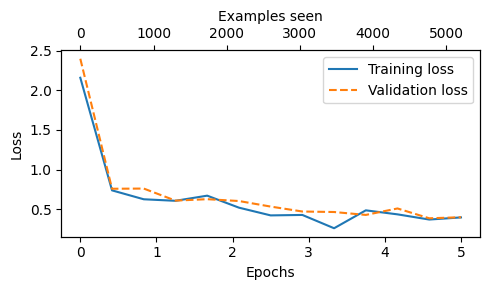

In [24]:
# 绘制分类损失曲线
import matplotlib.pyplot as plt

def plot_values(
    epochs_seen,
    examples_seen,
    train_values,
    val_values,
    label="loss"
):
    fig, ax1 = plt.subplots(figsize=(5, 3))
    ax1.plot(
        epochs_seen,
        train_values,
        linestyle="-",
        label=f"Training {label}"
    )
    ax1.plot(
        epochs_seen,
        val_values,
        linestyle="--",
        label=f"Validation {label}"
    )

    ax1.set_xlabel("Epochs")
    ax1.set_ylabel(label.capitalize())
    ax1.legend()
    ax2 = ax1.twiny()
    ax2.plot(
        examples_seen,
        train_values,
        alpha=0
    )
    ax2.set_xlabel("Examples seen")
    fig.tight_layout()
    plt.savefig(f"{label}-plot.pdf")
    plt.show()


epochs_tensor = torch.linspace(0, num_epochs, len(train_losses))
examples_seen_tensor = torch.linspace(0, examples_seen, len(train_losses))
plot_values(epochs_tensor, examples_seen_tensor, train_losses, val_losses)

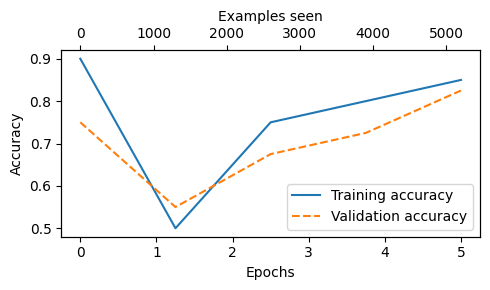

In [25]:
# 绘制分类准确率曲线
epochs_tensor = torch.linspace(0, num_epochs, len(train_accs))
examples_seen_tensor = torch.linspace(0, examples_seen, len(train_accs))

plot_values(
    epochs_tensor, examples_seen_tensor, train_accs, val_accs,
    label="accuracy"
)

In [26]:
# 微调后准确率
train_accuracy = calc_accuracy_loader(train_loader, gpt, device)
val_accuracy = calc_accuracy_loader(val_loader, gpt, device)
test_accuracy = calc_accuracy_loader(test_loader, gpt, device)

print(f"Training accuracy: {train_accuracy*100:.2f}%")
print(f"Validation accuracy: {val_accuracy*100:.2f}%")
print(f"Test accuracy: {test_accuracy*100:.2f}%")

Training accuracy: 82.79%
Validation accuracy: 82.55%
Test accuracy: 83.67%


In [27]:
# 使用模型对新的文本进行分类
def classify_review(text, model, tokenizer, device, max_length=None, pad_token_id=50256):
    model.eval()
    input_ids = tokenizer.encode(text)
    supported_context_length = model.pos_emb.weight.shape[1]
    # 截断过长的序列
    input_ids = input_ids[:min(
        max_length, supported_context_length
    )]
    input_ids += [pad_token_id] * (max_length - len(input_ids))
    input_tensor = torch.tensor(input_ids, device=device).unsqueeze(0)
    with torch.no_grad():
        logits = model(input_tensor)[:, -1, :]
    predicted_label = torch.argmax(logits, dim=-1).item()
    return "spam" if predicted_label == 1 else "not spam"

In [28]:
text_1 = (
    "You are a winner you have been specially"
    " selected to receive $1000 cash or a $2000 award."
)
print(classify_review(
    text_1, gpt, tokenizer, device, max_length=train_dataset.max_length
))

text_2 = (
    "Hey, just wanted to check if we're still on"
    " for dinner tonight? Let me know!"
)
print(classify_review(
    text_2, gpt, tokenizer, device, max_length=train_dataset.max_length
))

spam
not spam


In [29]:
# 保存模型
torch.save(gpt.state_dict(), "model/review_classifier.pth")

In [30]:
# 加载模型
model_state_dict = torch.load("model/review_classifier.pth", map_location=device)
gpt.load_state_dict(model_state_dict)

<All keys matched successfully>